In [1]:
#importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#pip install pandas matplotlib seaborn

*  Importing and understanding dataset

In [2]:
#reading csv file 
df = pd.read_csv("../data/student_habits_performance.csv")

In [3]:
#Data visualization

df

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,S1995,21,Female,2.6,0.5,1.6,No,77.0,7.5,Fair,2,High School,Good,6,Yes,76.1
996,S1996,17,Female,2.9,1.0,2.4,Yes,86.0,6.8,Poor,1,High School,Average,6,Yes,65.9
997,S1997,20,Male,3.0,2.6,1.3,No,61.9,6.5,Good,5,Bachelor,Good,9,Yes,64.4
998,S1998,24,Male,5.4,4.1,1.1,Yes,100.0,7.6,Fair,0,Bachelor,Average,1,No,69.7


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   str    
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   str    
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   str    
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   str    
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    str    
 12  internet_quality               1000 non-null   str    
 13  

* Which habits impact student performance the most?


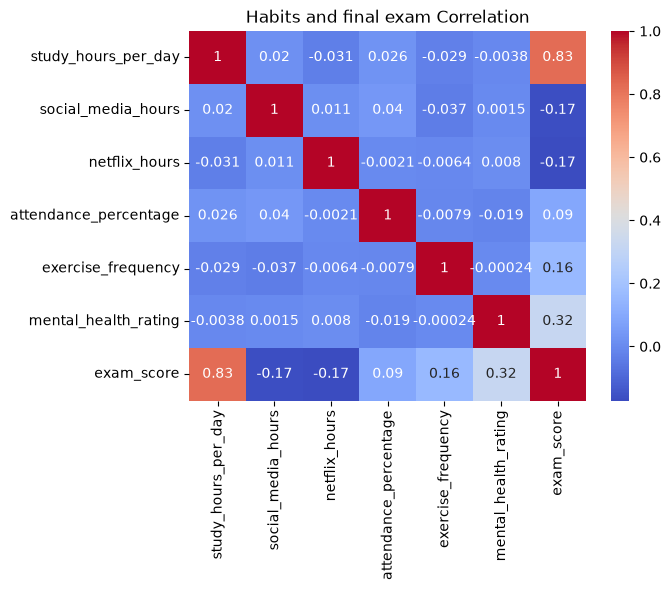

In [5]:
#heatmap - similar to confusion matrix

cols = [
    "study_hours_per_day",
    "social_media_hours",
    "netflix_hours",
    "attendance_percentage",
    "exercise_frequency",
    "mental_health_rating",
    "exam_score"
]

sns.heatmap(df[cols].corr(), annot = True, cmap = "coolwarm")
plt.title("Habits and final exam Correlation")
plt.show()

* Does studying more hours lead to better academic performance?

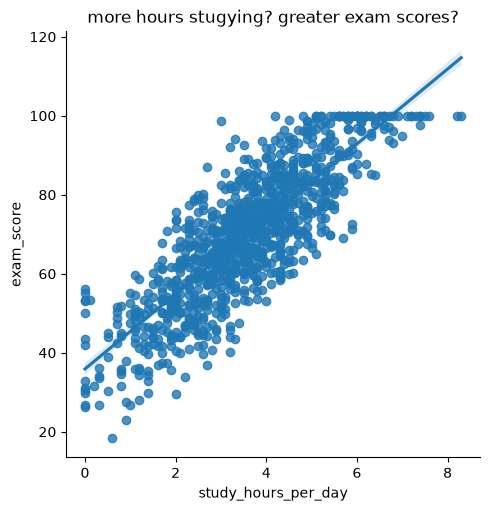

In [6]:
#dispersion graph

# x = study_hours_per_day 
# y  = exam_score (target variable - impact analization)

sns.lmplot(data = df, x = "study_hours_per_day", y = "exam_score")
plt.title("more hours stugying? greater exam scores?")
plt.show()




* How many students have part-time jobs?

In [7]:
#value counts and percentage of part time jobs

print(df["part_time_job"].value_counts())
print("\nPercentage: ")
print(df["part_time_job"].value_counts(normalize=True) * 100)

part_time_job
No     785
Yes    215
Name: count, dtype: int64

Percentage: 
part_time_job
No     78.5
Yes    21.5
Name: proportion, dtype: float64


* Scatter plot: Sleep hours vs Exam Score per Job Status

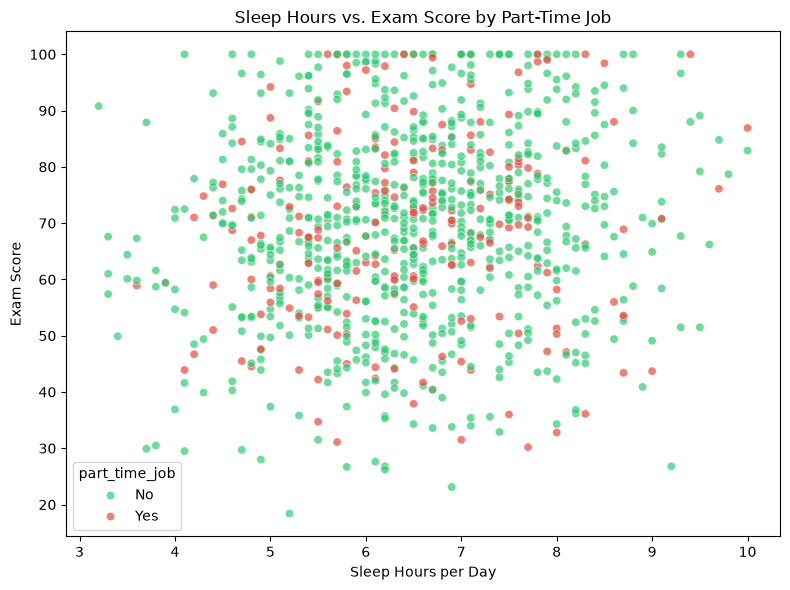

In [8]:
#defining grade criteria
df["score_category"] = df["exam_score"].apply(lambda x: "Above average" if x >= 70 else "Below Average")

plt.figure(figsize=(8, 6))

#Graph 1: Scatter plot - Sleep hours vs Exam Score per Job Status
sns.scatterplot(
    data = df,
    x = "sleep_hours",
    y = "exam_score",
    hue = "part_time_job",
    alpha = 0.7,
    palette = {"Yes": "#e74c3c", "No": "#2ecc71"},
    )
plt.title("Sleep Hours vs. Exam Score by Part-Time Job")
plt.xlabel("Sleep Hours per Day")
plt.ylabel("Exam Score")

plt.tight_layout()
plt.show()


In [9]:
import pandas as pd

# 1. Create performance category column
df["score_category"] = df["exam_score"].apply(lambda x: "Above Average" if x >= 70 else "Below Average")

# 2. Absolute Student Count Table
count_table = pd.crosstab(df['part_time_job'], df['score_category'], margins=True)

# 3. Relative Percentage Table within each group (%)
percentage_table = pd.crosstab(df['part_time_job'], df['score_category'], normalize='index') * 100

print("=== ABSOLUTE STUDENT COUNT ===")
print(count_table)
print("\n=== PERCENTAGE WITHIN EACH GROUP (%) ===")
print(percentage_table.round(2))

=== ABSOLUTE STUDENT COUNT ===
score_category  Above Average  Below Average   All
part_time_job                                     
No                        408            377   785
Yes                       103            112   215
All                       511            489  1000

=== PERCENTAGE WITHIN EACH GROUP (%) ===
score_category  Above Average  Below Average
part_time_job                               
No                      51.97          48.03
Yes                     47.91          52.09


In [10]:
# Comparing means: students studying >5h vs <2h
high_study_filter = df["study_hours_per_day"] > 5
low_study_filter = df["study_hours_per_day"] < 2

high_study_group = df[high_study_filter]["exam_score"]
low_study_group = df[low_study_filter]["exam_score"]

print("Average score (studies >5h):", high_study_group.mean())
print("Average score (studies <2h):", low_study_group.mean())


Average score (studies >5h): 90.79419354838709
Average score (studies <2h): 45.56390977443609


* Does time spent on social media affect students' academic performance? 


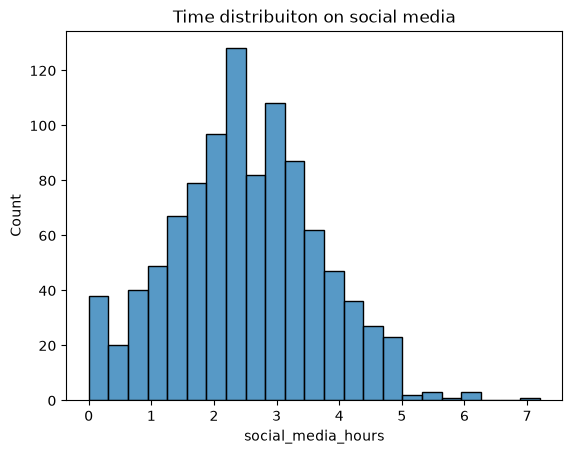

In [11]:
#Social media: histogram
#x = "social_media_hours"

sns.histplot(data = df, x = "social_media_hours")
plt.title("Time distribuiton on social media")
plt.show()

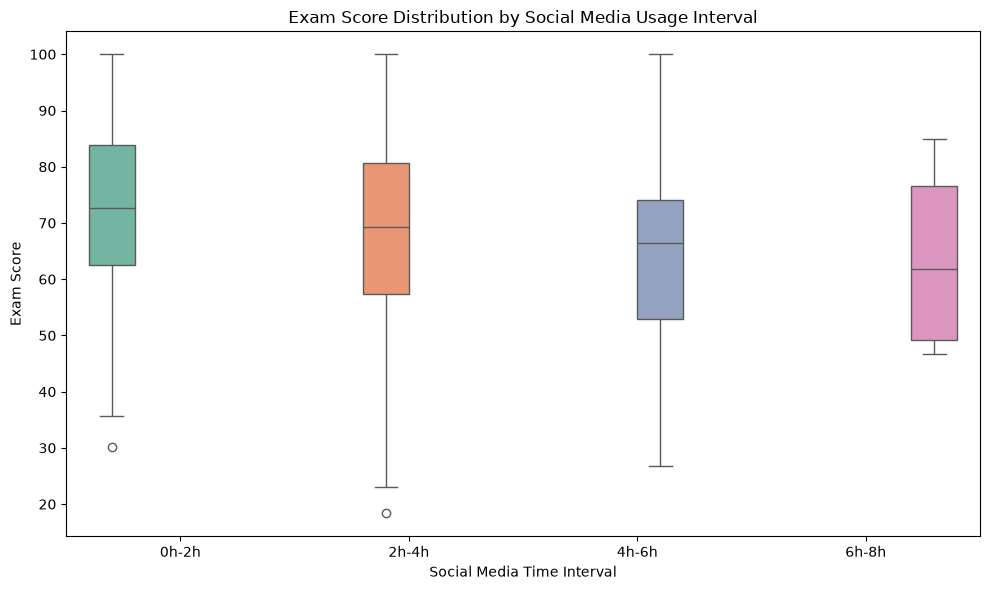

In [12]:
# Evaluating average scores across different social media usage intervals (bins)
# ["0-2h", "2h-4h", "4h-6h", "6h+"]

df["social_media_bin"] = pd.cut(
    df["social_media_hours"],
    bins = [0, 2, 4, 6, float("inf")],
    labels = ["0h-2h", "2h-4h", "4h-6h", "6h-8h"],
    right = False
)
## Plot boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(
    x="social_media_bin", 
    y="exam_score", 
    data=df, 
    hue="social_media_bin", 
    palette="Set2", 
    legend=False
)
plt.title("Exam Score Distribution by Social Media Usage Interval")
plt.xlabel("Social Media Time Interval")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show()

* Do healthy habits lead to better academic performance?

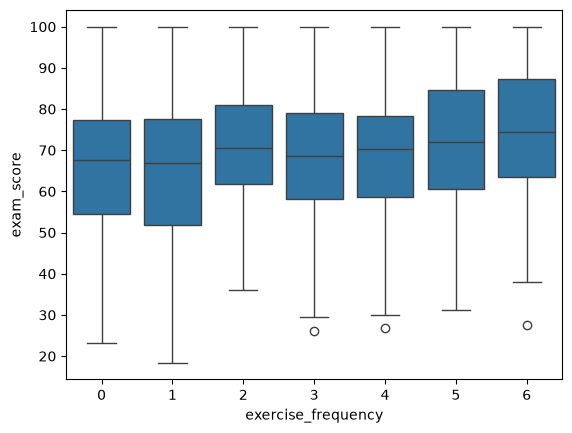

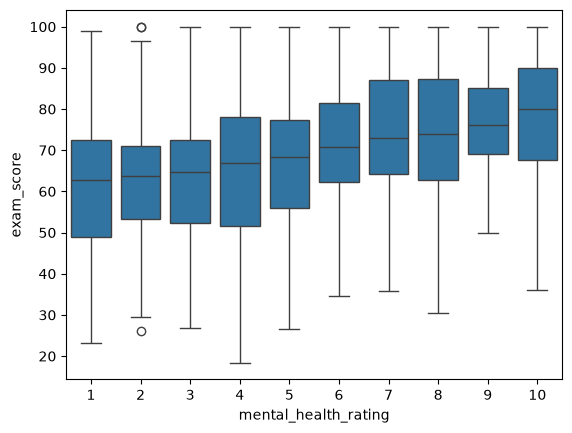

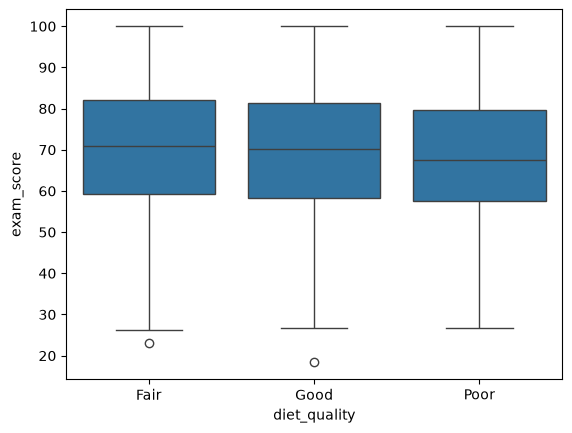

In [13]:
#PE frequency
for col  in ["exercise_frequency", "mental_health_rating", "diet_quality"]:
    sns.boxplot( x = col, y = "exam_score", data = df)
    plt.show()

In [14]:
# good exercise frequency may lead to good academic performance 
# greater mental health rating leads to a better median average 
# good and fair diet quality lead to better exam score average (low significance)

* Is there a difference in exam scores between females and males?

In [15]:
# Statistics by gender (mean and standard deviation)
df.groupby(["gender"])["exam_score"].agg(["mean", "std"])

,mean,std
gender,,
Female,69.741372,16.899351
Male,69.368344,17.150875
Other,70.647619,13.755890


* means are very similar
* male std deviation is slighltly 


In [16]:
# Evaluate gender distribution
df["gender"].value_counts(normalize = True)

gender
Female    0.481
Male      0.477
Other     0.042
Name: proportion, dtype: float64

* Males and females are the two most marked gender on dataframe
* The "Other" gender represents roughly 4% of the smaple, making it insufficient for comparsion.